In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:45951")
client

<Client: 'tcp://127.0.0.1:45951' processes=10 threads=40, memory=629.62 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [ ]:
for pp in range(6,9):
    ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                        ).chunk({"time":10,"y":400,"x":400})
    
    ke = .5*(ds["u.x"]**2 + ds["u.y"]**2).where(ds.h > 0.)
    hke = ds.h * ke

    Hke = (hke.sum("level", skipna=True) 
           / ds.h.sum("level", skipna=True))
    dsave = Hke.to_dataset(name="ke")
    dsave.to_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" % pp),
                  mode="w")
    dsave.close()
    ds.close()

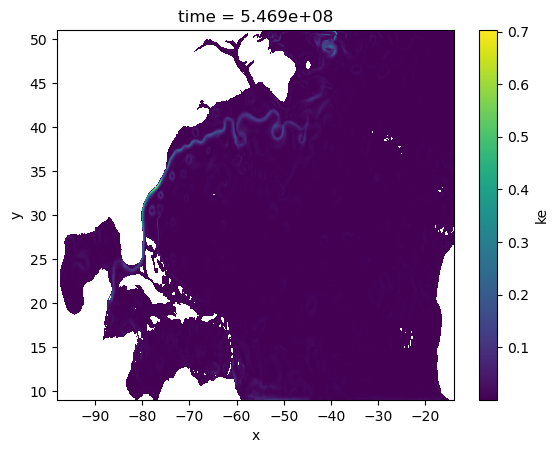

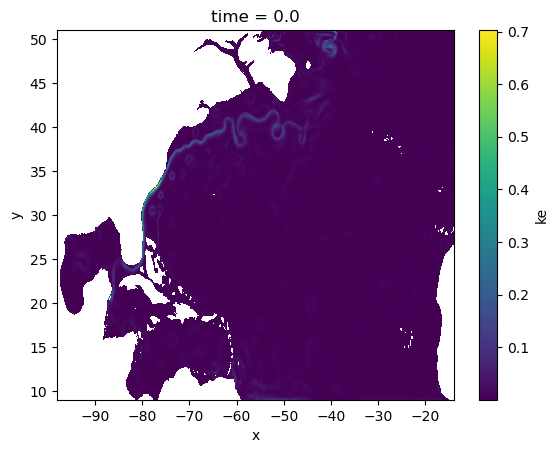

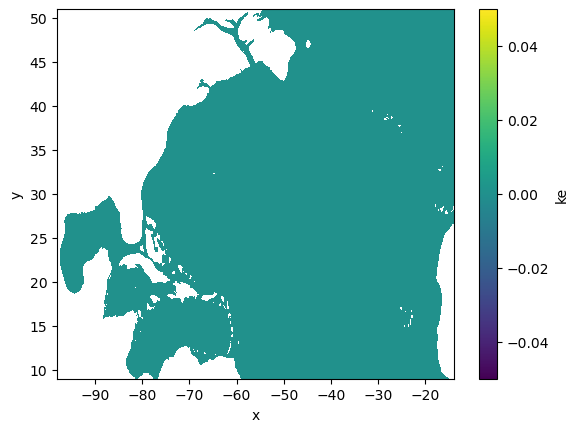

In [5]:
ds = xr.open_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" % 6))
ke6 = ds.ke
ke6.isel(time=-1).plot(rasterized=True)
plt.show()
ds = xr.open_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" % 7))
ke7 = ds.ke
ke7.isel(time=0).plot(rasterized=True)
plt.show()
(ke7.isel(time=0)-ke6.isel(time=-1)).plot(rasterized=True)

In [8]:
for pp in range(6,7):
    ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                        ).chunk({"time":10,"y":400,"x":400})
    
    h2 = .5*((ds.h.where(ds.h > 0.) 
              - ds.h.where(ds.h > 0.).mean(["y","x"],skipna=True)
             )**2)
    h2 = ds.h * h2

    Hh2 = (h2.sum("level", skipna=True) 
           / ds.h.sum("level", skipna=True))
    dsave = Hh2.to_dataset(name="h2")
    dsave.to_zarr(op.join(ddir,"SW/h2/VertAve_p%02d.zarr" % pp),
                  mode="w")
    dsave.close()
    ds.close()

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


In [6]:
for pp in range(1,9):
    if pp == 1:
        dske = xr.open_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" 
                                    % pp))
    else:
        # try:
        tmp = xr.open_zarr(op.join(ddir,"SW/KE/VertAve_p%02d.zarr" 
                                   % pp)
                          ).isel(time=slice(1,None))
        time = tmp.time.data + dske.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time",time)
        dske = xr.concat([dske, 
                          tmp
                         ], "time")
        # except:
        #     pass
dske

<xarray.Dataset> Size: 54GB
Dimensions:  (time: 1612, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 6kB 0.0 2.592e+06 5.184e+06 ... 4.173e+09 4.176e+09
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    ke       (time, y, x) float32 54GB dask.array<chunksize=(10, 400, 400), meta=np.ndarray>

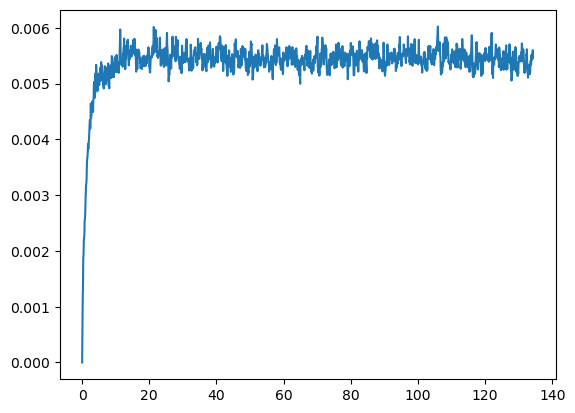

In [13]:
fig, ax = plt.subplots()
ax.plot(dske.time/86400./360.,
        dske.ke.mean(["y","x"], skipna=True)
       )

In [11]:
for pp in range(1,9):
    if pp == 1:
        dsh2 = xr.open_zarr(op.join(ddir,"SW/h2/VertAve_p%02d.zarr" 
                                    % pp))
    else:
        # try:
        tmp = xr.open_zarr(op.join(ddir,"SW/h2/VertAve_p%02d.zarr" 
                                   % pp)
                          ).isel(time=slice(1,None))
        time = tmp.time.data + dsh2.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time",time)
        dsh2 = xr.concat([dsh2, 
                          tmp
                         ], "time")
        # except:
        #     pass
dsh2

<xarray.Dataset> Size: 54GB
Dimensions:  (time: 1612, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 6kB 0.0 2.592e+06 5.184e+06 ... 4.173e+09 4.176e+09
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h2       (time, y, x) float32 54GB dask.array<chunksize=(10, 400, 400), meta=np.ndarray>

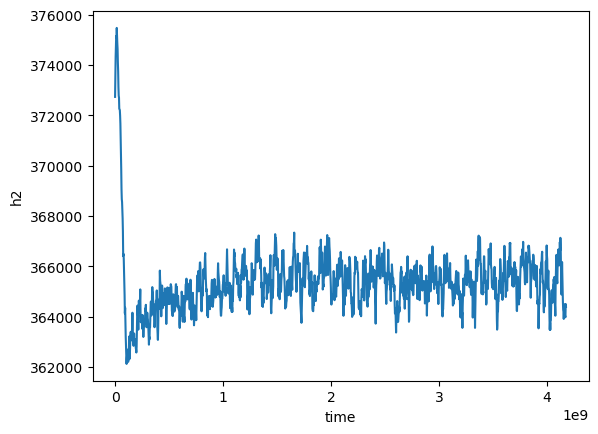

In [12]:
dsh2.h2.mean(["y","x"], skipna=True).plot()

In [4]:
for pp in range(6,9):
    if pp == 6:
        ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).chunk({"time":4,"level":1,"y":128,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   # level=slice(1,None)
                                  ).chunk({"time":4,"level":1,"y":128,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 317GB
Dimensions:  (time: 630, level: 5, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>

In [5]:
dsb = xr.open_zarr(op.join(ddir,"SW/48/mean/UVh.zarr")
                  ).chunk({"level":1,"y":128,"x":256}
                         )
dsp = xr.open_zarr(op.join(ddir,"SW/48/TWA/Up.zarr")
                  ).chunk({"level":1,"y":128,"x":256}
                         )
print(dsb, dsp)
EKE = .5*(dsp.up**2 + dsp.vp**2).mean("time").compute()
MKE = .5*(dsb.ubar**2 + dsb.vbar**2)
EKE

<xarray.Dataset> Size: 671MB
Dimensions:  (level: 4, y: 2048, x: 4096)
Coordinates:
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    hbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    ubar     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    uhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    vbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray>
    vhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 128, 256), meta=np.ndarray> <xarray.Dataset> Size: 169GB
Dimensions:  (time: 630, level: 4, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 15.47 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.DataArray (level: 4, y: 2048, x: 4096)> Size: 134MB
array([[[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        ...,
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         3.58991529e-05, 2.29834059e-05, 1.16254323e-05],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         1.68680617e-05, 9.37404093e-06, 4.68348435e-06],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         8.01662100e-06, 2.53243184e-06, 6.09666813e-07]],

       [[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
...
         1.18367519e-04, 7.39463358e-05, 3.75042691e-05],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         5.50552832e-05, 2.92500354e-05, 1.37171955e-05],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         2.46365835e-05, 7.63508888e-06, 1.65310882e-06]],

       [[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        ...,
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         1.88419421e-04, 1.15499301e-04, 6.01026222e-05],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         8.61389053e-05, 4.64444893e-05, 2.34284144e-05],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         3.91509311e-05, 1.26913837e-05, 2.88854289e-06]]],
      shape=(4, 2048, 4096), dtype=float32)
Coordinates:
  * level    (level) float32 16B 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01

In [6]:
ssh = xr.open_zarr(op.join(ddir,"SW/48/SSH.zarr")).ssh
sshb = ssh.mean("time").compute()

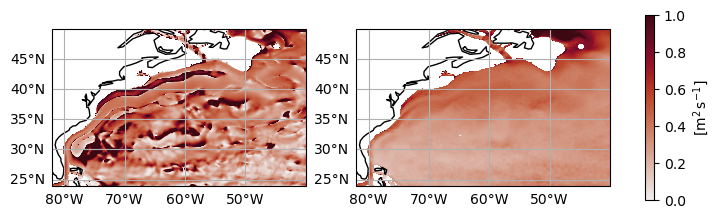

In [7]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

# fig = plt.figure(figsize=(9,4))
# ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
# ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
fig, axes = plt.subplots(
    figsize=(9,4), nrows=1, ncols=2,
    subplot_kw={"projection": ccrs.PlateCarree()},
)
ax1, ax2 = axes

ax1.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())
ax2.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())

ax1.coastlines(resolution='110m')
ax2.coastlines(resolution='110m')

gl1 = ax1.gridlines(draw_labels=True)
gl1.top_labels = False
gl1.right_labels = False
gl2 = ax2.gridlines(draw_labels=True)
gl2.top_labels = False
gl2.right_labels = False

im = ax1.pcolormesh(dsb.x, dsb.y, 
               MKE.isel(level=-2)/MKE.isel(level=-1), 
               cmap=cmocean.cm.amp,
               # cmap="bwr",
               vmin=0, vmax=1,
              )
ax2.pcolormesh(dsb.x, dsb.y, 
               EKE.isel(level=-2)/EKE.isel(level=-1),  
               cmap=cmocean.cm.amp,
               # cmap="bwr",
               vmin=0, vmax=1,
              )

# ax1.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
#             levels=np.array([0.,]), 
#             colors="lime", linestyles="dashed", linewidths=1)
# ax2.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
#             levels=np.array([0.,]), 
#             colors="lime", linestyles="dashed", linewidths=1)

ax1.set_rasterized(True)
ax2.set_rasterized(True)

# ax1.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^1/\Pi^\sharp_\tilde{x}$", 
#               fontsize=11)
# ax2.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^2/\Pi^\sharp_\tilde{y}$", 
#               fontsize=11)

cb = fig.colorbar(im, ax=axes, shrink=.6)
cb.set_label(r"[m$^2\,$s$^{-1}$]")

plt.savefig(op.join(ddir,"Figs/KE_SWratio.pdf"), dpi=200)

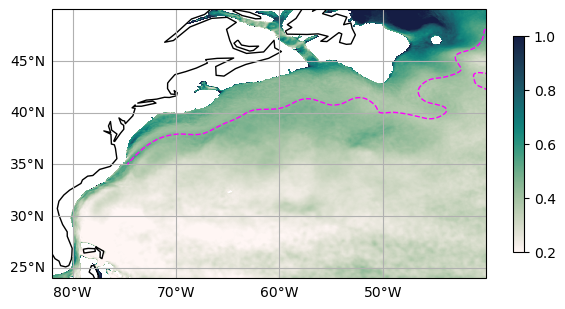

In [15]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

# fig = plt.figure(figsize=(9,4))
# ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
# ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
fig, ax = plt.subplots(
    figsize=(7,4),
    subplot_kw={"projection": ccrs.PlateCarree()},
)

ax.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())

ax.coastlines(resolution='110m')

gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsb.x, dsb.y, 
               EKE.isel(level=-2)/EKE.isel(level=-1),  
               cmap=cmocean.cm.tempo,
               # cmap="bwr",
               vmin=0.2, vmax=1.,
              )

ax.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="magenta", linestyles="dashed", linewidths=1)

ax.set_rasterized(True)

# ax1.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^1/\Pi^\sharp_\tilde{x}$", 
#               fontsize=11)
# ax2.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^2/\Pi^\sharp_\tilde{y}$", 
#               fontsize=11)

cb = fig.colorbar(im, ax=ax, shrink=.7)

plt.savefig(op.join(ddir,"Figs/EKE_SWratio2-1.pdf"), dpi=200)

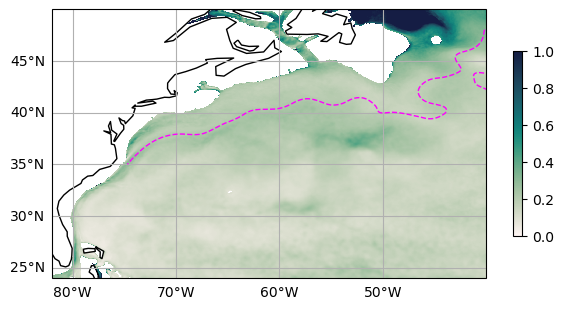

In [12]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

# fig = plt.figure(figsize=(9,4))
# ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
# ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
fig, ax = plt.subplots(
    figsize=(7,4),
    subplot_kw={"projection": ccrs.PlateCarree()},
)

ax.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())

ax.coastlines(resolution='110m')

gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsb.x, dsb.y, 
               EKE.isel(level=-3)/EKE.isel(level=-1),  
               cmap=cmocean.cm.tempo,
               # cmap="bwr",
               vmin=0, vmax=1.,
              )

ax.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="magenta", linestyles="dashed", linewidths=1)

ax.set_rasterized(True)

# ax1.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^1/\Pi^\sharp_\tilde{x}$", 
#               fontsize=11)
# ax2.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^2/\Pi^\sharp_\tilde{y}$", 
#               fontsize=11)

cb = fig.colorbar(im, ax=ax, shrink=.6)

plt.savefig(op.join(ddir,"Figs/EKE_SWratio3-1.pdf"), dpi=200)

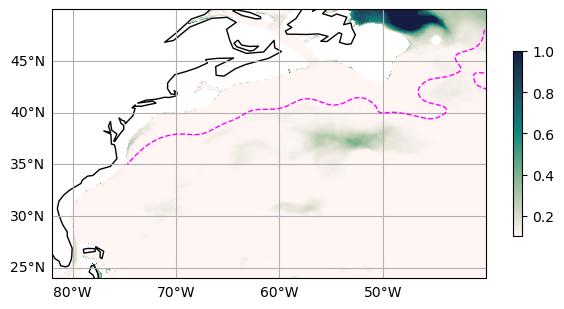

In [16]:
xmax = -40
xmin = -82
ymin = 24
ymax = 50

# fig = plt.figure(figsize=(9,4))
# ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
# ax2 = fig.add_subplot(1, 2, 2, projection=ccrs.PlateCarree())
fig, ax = plt.subplots(
    figsize=(7,4),
    subplot_kw={"projection": ccrs.PlateCarree()},
)

ax.set_extent([xmin, xmax, ymin, ymax], 
              crs=ccrs.PlateCarree())

ax.coastlines(resolution='110m')

gl = ax.gridlines(draw_labels=True)
gl.top_labels = False
gl.right_labels = False

im = ax.pcolormesh(dsb.x, dsb.y, 
               EKE.isel(level=-4)/EKE.isel(level=-1),  
               cmap=cmocean.cm.tempo,
               # cmap="bwr",
               vmin=0.1, vmax=1.,
              )

ax.contour(dsb.x, dsb.y, sshb.where(sshb.y>35.), 
            levels=np.array([0.,]), 
            colors="magenta", linestyles="dashed", linewidths=1)

ax.set_rasterized(True)

# ax1.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^1/\Pi^\sharp_\tilde{x}$", 
#               fontsize=11)
# ax2.set_title(r"$-{\mathcal{J}^{\Pi}_{\tt SW}}^2/\Pi^\sharp_\tilde{y}$", 
#               fontsize=11)

cb = fig.colorbar(im, ax=ax, shrink=.6)

plt.savefig(op.join(ddir,"Figs/EKE_SWratio4-1.pdf"), dpi=200)